# Week 3 - Day 1

# Data Cleaning and Preprocessing

In the previous lesson, we learned how to load and visualize a dataset.

Before building a Machine Learning model, we must first ensure our data is clean and ready for analysis.

In this lesson, you'll learn how to identify and handle common data quality issues.

## Learning Objectives

By the end of this lesson, you should be able to:

- Identify missing values.
- Detect duplicate records.
- Handle missing data.
- Remove duplicate rows.
- Prepare a dataset for Machine Learning.

In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("student_performance.csv")

df.head()

,Student_ID,Name,Gender,Age,Department,Attendance,Study_Hours,Assignment_Score,Quiz_Score,Exam_Score,Final_Score,Pass
0,STU001,Joy Ibekwe,Male,23,Computer Science,100.0,4.4,45,44.0,42,43.0,No
1,STU002,Sarah Olatunji,Male,22,AI Engineering,97.0,8.5,57,51.0,53,53.4,Yes
2,STU003,Mariam Abdullahi,Female,20,Data Science,94.0,8.5,71,71.0,61,65.0,Yes
3,STU004,Hannah Uche,Female,24,Data Science,69.0,5.8,54,49.0,46,48.2,No
4,STU005,Daniel Ogunbiyi,Male,22,Data Science,98.0,6.4,48,54.0,55,53.4,Yes


## Why Do We Clean Data?

Real-world datasets are rarely perfect.

Some records may have missing values, duplicate entries, or incorrect information.

Cleaning the data helps improve the accuracy of our analysis and Machine Learning models.

## Identifying Missing Values

A missing value is information that is unavailable or was not recorded.

Pandas provides the `isnull()` function to detect missing values.

In [3]:
df.isnull()

,Student_ID,Name,Gender,Age,Department,Attendance,Study_Hours,Assignment_Score,Quiz_Score,Exam_Score,Final_Score,Pass
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
97,False,False,False,False,False,False,False,False,False,False,False,False
98,False,False,False,False,False,False,False,False,False,False,False,False
99,False,False,False,False,False,False,False,False,False,False,False,False
100,False,False,False,False,False,True,False,False,False,False,False,False


The output shows **True** where a value is missing and **False** where data exists.

Since large datasets can be difficult to inspect visually, let's count the missing values in each column.

In [4]:
df.isnull().sum()

Student_ID          0
Name                0
Gender              0
Age                 0
Department          0
Attendance          5
Study_Hours         3
Assignment_Score    0
Quiz_Score          3
Exam_Score          0
Final_Score         0
Pass                0
dtype: int64

### Observation

Each number represents the total missing values in that column.

Columns with **0** have no missing values.

## Filling Missing Values

Instead of removing rows immediately, we can replace missing values with meaningful values.

For numerical columns, a common approach is to use the column's average (mean).

In [5]:
df["Attendance"] = df["Attendance"].fillna(df["Attendance"].mean())

df["Study_Hours"] = df["Study_Hours"].fillna(df["Study_Hours"].mean())

df["Quiz_Score"] = df["Quiz_Score"].fillna(df["Quiz_Score"].mean())

In [6]:
df.isnull().sum()

Student_ID          0
Name                0
Gender              0
Age                 0
Department          0
Attendance          0
Study_Hours         0
Assignment_Score    0
Quiz_Score          0
Exam_Score          0
Final_Score         0
Pass                0
dtype: int64

### Observation

The missing values have been replaced.

Notice that the number of missing values is now **0** for the columns we cleaned.

## Identifying Duplicate Rows

Duplicate rows occur when the same record appears more than once.

Pandas provides the `duplicated()` function to detect duplicates.

In [7]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
97     False
98     False
99     False
100     True
101     True
Length: 102, dtype: bool

In [8]:
df.duplicated().sum()

np.int64(2)

The output tells us how many duplicate rows exist in the dataset.

## Removing Duplicate Rows

Duplicate records can affect analysis and Machine Learning models.

The `drop_duplicates()` function removes repeated rows.

In [9]:
df = df.drop_duplicates()

In [10]:
df.duplicated().sum()

np.int64(0)

### Observation

The duplicate rows have been removed successfully.

## Identifying Outliers

An **outlier** is a value that is much higher or lower than the rest of the data.

Outliers can affect statistics and Machine Learning models, so it's important to identify them before training a model.

### Using a Box Plot

A **box plot** helps us quickly identify outliers in a dataset.

Values that appear far away from the main group are potential outliers.

## What is `boxplot()`?

A box plot is a chart used to identify the spread of data and detect possible outliers.

```python
plt.boxplot(df["Study_Hours"])
```

Here:

- **plt** refers to Matplotlib.
- **boxplot()** creates the chart.
- **df["Study_Hours"]** tells Matplotlib to visualize the **Study_Hours** column.

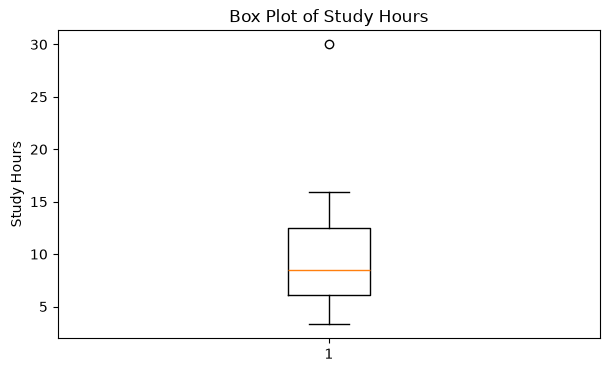

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,4))

plt.boxplot(df["Study_Hours"].dropna())

plt.title("Box Plot of Study Hours")
plt.ylabel("Study Hours")

plt.show()

### Observation

Notice any points that appear outside the main box.

These values are potential outliers and should be investigated before building a Machine Learning model.

## Understanding the Data

Before deciding whether a value is unusual, it's helpful to look at some basic statistics.

The `describe()` function summarizes numerical columns.

In [12]:
df.describe()

,Age,Attendance,Study_Hours,Assignment_Score,Quiz_Score,Exam_Score,Final_Score
count,100.000000,100.000000,100.000000,100.000000,100.000000,100.00000,100.000000
mean,21.330000,80.041237,9.237879,67.370000,67.691515,66.85000,67.106000
std,1.933516,13.221438,4.079922,18.128974,18.542504,18.85906,18.368296
min,18.000000,25.000000,3.300000,40.000000,40.000000,40.00000,40.000000
25%,19.750000,70.000000,6.100000,51.750000,52.750000,49.75000,49.900000
50%,22.000000,81.000000,8.500000,65.000000,67.191919,66.50000,65.500000
75%,23.000000,91.250000,12.450000,82.250000,83.000000,81.75000,84.300000
max,24.000000,100.000000,30.000000,100.000000,100.000000,100.00000,100.000000


The output shows useful statistics such as:

- Mean (Average)
- Minimum value
- Maximum value
- Standard deviation
- Quartiles (25%, 50%, 75%)

These help us understand how the data is distributed.

## Saving the Cleaned Dataset

After cleaning a dataset, it's good practice to save the cleaned version instead of repeating the cleaning process every time.

In [13]:
df.to_csv("student_performance_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


The cleaned dataset has been saved as:

**student_performance_cleaned.csv**

We'll use this file in future Machine Learning lessons.

# Mini Practical Activity

Perform the following tasks:

1. Load the dataset.
2. Check for missing values.
3. Fill missing values using the column mean.
4. Check for duplicate rows.
5. Remove duplicate rows.
6. Display the first five rows of the cleaned dataset.

### Exercise 1

Display the total number of missing values in each column.

### Exercise 2

Check whether the dataset contains duplicate rows.

If duplicates exist, remove them.

### Exercise 3

Create a box plot for the **Exam_Score** column and write one observation about the chart.

# Lesson Summary

In this lesson, you learned how to:

- Identify missing values.
- Fill missing values using the mean.
- Detect duplicate rows.
- Remove duplicate records.
- Identify outliers using a box plot.
- Save a cleaned dataset for future analysis.

These preprocessing techniques are essential before training Machine Learning models.

## What is Scikit-learn (sklearn)?

**Scikit-learn**, commonly written as **sklearn**, is one of the most popular Machine Learning libraries in Python.

It provides ready-made tools for tasks such as:

- Preparing data
- Training Machine Learning models
- Evaluating model performance
- Making predictions

Throughout this bootcamp, we'll use many tools from Scikit-learn.

## What is Preprocessing?

Before training a Machine Learning model, data often needs to be prepared.

This process is called **preprocessing**.

Examples of preprocessing include:

- Filling missing values
- Scaling numerical values
- Encoding text into numbers

Scikit-learn provides a module called **`sklearn.preprocessing`** that contains tools for performing these tasks.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

### Understanding the Import

```python
from sklearn.preprocessing import MinMaxScaler
```

Let's break it down:

- **sklearn** → The Scikit-learn library.
- **preprocessing** → A module for preparing data before Machine Learning.
- **MinMaxScaler** → A tool used to scale numerical values between **0** and **1**.

## What is Normalization?

Different features may have different scales.

For example:

- Attendance ranges from **0–100**
- Study Hours range from **3–30**

Normalization scales numerical values to a common range (usually **0 to 1**), making them easier for Machine Learning models to learn from.

## Why Do We Normalize Data?

Machine Learning models learn better when numerical features have similar scales.

Consider these two features:

| Feature | Values |
|---------|---------|
| Attendance | 60–100 |
| Study Hours | 2–15 |

Attendance has much larger numbers than Study Hours.

Some Machine Learning algorithms may give more importance to larger values simply because of their scale.

Normalization solves this problem by converting all values to a common range between **0** and **1**.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

`MinMaxScaler` transforms values using the formula:

\[
\frac{x - min}{max - min}
\]

After normalization, every value falls between **0** and **1**.

In [ ]:
scaler = MinMaxScaler()

df["Study_Hours_Normalized"] = scaler.fit_transform(df[["Study_Hours"]])

df.head()

### Understanding `fit_transform()`

```python
scaler.fit_transform(df[["Study_Hours"]])
```

This performs two steps:

- **fit()** → Learns the minimum and maximum values in the column.
- **transform()** → Uses those values to scale every record between **0** and **1**.

`fit_transform()` combines both steps into a single command.

### Observation

Notice the new column **Study_Hours_Normalized**.

The values are now between **0** and **1**.

## What is Encoding?

**Encoding is the process of converting categorical data into a numerical format that Machine Learning models can understand and process.**

For example, our dataset contains:

- Gender → Female, Male
- Department → Computer Science, Data Science, AI Engineering

These are categorical values represented as text. Since many Machine Learning algorithms work with numerical data, we need to convert these categories into numbers.

There are different ways to do this. In this lesson, we will focus on two common techniques:

1. **Label Encoding**
2. **One-Hot Encoding**

## 1. Label Encoding

**Label Encoding converts each category into a numerical value.**

For example:

| Gender | Encoded Value |
|---|---:|
| Female | 0 |
| Male | 1 |

### When should we use it?

Label Encoding is most useful when the categories have a meaningful order, such as:

Low → 0  
Medium → 1  
High → 2

However, be careful when categories have **no natural order**, because a model may interpret the numbers as having a ranking.

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["Gender_Encoded"] = encoder.fit_transform(df["Gender"])

df.head()

In [ ]:
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

df["Gender_Encoded"] = encoder.fit_transform(df["Gender"])

df[["Gender", "Gender_Encoded"]].head()

## 2. One-Hot Encoding

**One-Hot Encoding creates a separate column for each category and represents membership using 0 and 1.**

For example:

| Department | Computer Science | Data Science | AI Engineering |
|---|---:|---:|---:|
| Computer Science | 1 | 0 | 0 |
| Data Science | 0 | 1 | 0 |
| AI Engineering | 0 | 0 | 1 |

### When should we use it?

One-Hot Encoding is useful when categories have **no natural order**, such as departments, countries, colours, or cities.

It prevents the model from assuming that one category is "greater" than another.

In [ ]:
encoded_df = pd.get_dummies(df, columns=["Gender"], dtype=int)

encoded_df.head()

In [ ]:
encoded_df = pd.get_dummies(
    df,
    columns=["Department"],
    dtype=int
)

encoded_df.head()

## Label Encoding vs One-Hot Encoding

| | Label Encoding | One-Hot Encoding |
|---|---|---|
| How it works | Converts categories to numbers | Creates a binary column for each category |
| Example | Male → 1, Female → 0 | Male → `[1,0]`, Female → `[0,1]` |
| Best for | Categories that have an order, with care | Categories with no natural orders |
| Number of columns | Usually stays as one | Creates multiple columns |
| Main concern | Can imply a false ranking | Can create many columns |


Both techniques convert categorical data into numbers, but they do it differently.

**Label Encoding** keeps the categories in one column and assigns each category a number.

**One-Hot Encoding** creates a separate column for each category and uses `0` and `1` to represent membership.

The choice depends on the type of categorical data and the Machine Learning model we plan to use.

## Other Encoding Techniques

Label Encoding and One-Hot Encoding are not the only ways to encode categorical data.

As datasets become larger or contain many unique categories, data scientists may use techniques such as:

- **Ordinal Encoding** – assigns numbers according to a known order.
- **Target Encoding** – represents categories using information from the target variable.
- **Frequency Encoding** – represents categories based on how often they occur.
- **Binary Encoding** – represents categories using binary values.
- **Feature Hashing** – converts categories into a fixed number of numerical features.

These techniques are useful in more advanced Machine Learning workflows and will not be implemented in this lesson.

## Understanding `pd.get_dummies()`

```python
pd.get_dummies(df, columns=["Gender"])
```

- **pd** refers to the Pandas library.
- **get_dummies()** converts text categories into numerical columns.
- **columns=["Gender"]** tells Pandas which column to encode.

# Mini Practical Activity

Using the dataset:

1. Check for missing values.
2. Fill missing values.
3. Remove duplicate rows.
4. Normalize the **Study_Hours** column.
5. Encode the **Gender** column.
6. Display the first 5 rows.

### Exercise 1

Normalize the **Attendance** column using `MinMaxScaler`.

### Exercise 2

Use One-Hot Encoding on the **Department** column.

### Exercise 3

Save the cleaned dataset as:

`student_performance_cleaned.csv`

# Lesson Summary

Today, you learned how to:

- Identify and handle missing values.
- Remove duplicate records.
- Normalize numerical data.
- Encode categorical variables.
- Prepare a dataset for Machine Learning.

Your dataset is now ready for visualization and model training.

# Functions and Concepts Learned Today

The table below summarizes the major libraries, functions, and concepts introduced in this lesson.

| Item | Purpose |
|------|---------|
| `df.isnull()` | Checks every cell in the dataset for missing values. Returns `True` for missing values and `False` otherwise. |
| `df.isnull().sum()` | Counts the total number of missing values in each column. |
| `fillna()` | Replaces missing values with a specified value, such as the column mean. |
| `mean()` | Calculates the average value of a numerical column. |
| `duplicated()` | Checks whether rows are repeated in the dataset. |
| `drop_duplicates()` | Removes duplicate rows from the dataset. |
| `describe()` | Displays summary statistics such as mean, minimum, maximum and quartiles. |
| `plt.figure()` | Creates the figure (canvas) where a chart will be displayed. |
| `figsize=(7,4)` | Sets the width and height of the figure. |
| `plt.boxplot()` | Creates a box plot to visualize data distribution and identify possible outliers. |
| `plt.title()` | Adds a title to the chart. |
| `plt.ylabel()` | Labels the vertical (y) axis. |
| `plt.show()` | Displays the completed chart. |
| `to_csv()` | Saves a DataFrame as a CSV file. |
| `index=False` | Prevents Pandas from saving row numbers as an extra column in the CSV file. |
| `sklearn` | A Python library used for Machine Learning. |
| `sklearn.preprocessing` | A Scikit-learn module that provides tools for preparing data before model training. |
| `MinMaxScaler` | Scales numerical values to a range between 0 and 1 (Normalization). |
| `fit()` | Learns the minimum and maximum values from the data. |
| `transform()` | Applies the learned scaling to the data. |
| `fit_transform()` | Performs both `fit()` and `transform()` in one step. |
| `pd.get_dummies()` | Converts categorical (text) data into numerical columns using One-Hot Encoding. |
| `One-Hot Encoding` | Converts categorical values into binary (0 and 1) columns so Machine Learning models can understand them. |
| `Normalization` | Scales numerical values to a common range (usually 0–1) so that features contribute fairly during model training. |
| `Outlier` | A value that is significantly higher or lower than the rest of the data. |